# Praktikum Komputasi Numerik
## Modul 6: Turunan Numerik (Beda Maju, Mundur, dan Titik Tengah)

|  |  |
|---|---|
| Nama | Fathin Yassarahman |
| NIM | 241524041 |
| Kelas | 5B |
| Program Studi | D-4 Teknik Informatika |
| Jurusan | Teknik Komputer dan Informatika, Politeknik Negeri Bandung |
| Tanggal | 10 November 2026 |

isi notebook: Task I sampai Task IV, jawaban Tugas Praktikum (III.8), dan Soal Latihan HOTS gaya ICPC (III.9).

fungsi uji utama adalah f(x) = x^2 sin x di x0 = 1 dengan turunan eksak f'(1) = 2.2232443. data tabular yang dipakai adalah posisi sensor s = 45t^2 dan tabel tujuh titik dari Munir (2021, Contoh 7.1).

---
# Task 0: Setup Environment

memeriksa python, numpy, dan matplotlib sebelum masuk materi. semua skim beda hingga ditulis sendiri, sedangkan `math` hanya dipakai untuk nilai fungsi dan turunan eksak pembanding

In [1]:
print("Hello, Modul 6!")

import sys
print("Python version:", sys.version.split()[0])

import math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
print("NumPy version     :", np.__version__)
print("Matplotlib version:", matplotlib.__version__)

Hello, Modul 6!
Python version: 3.13.18


NumPy version     : 2.5.3
Matplotlib version: 3.11.2


---
# Task I: Beda Maju, Mundur, dan Titik Tengah

turunan f(x) = x^2 sin x di x0 = 1 dihitung dengan tiga skim beda hingga. turunan eksaknya f'(x) = 2x sin x + x^2 cos x, sehingga galat tiap skim bisa diukur persis

In [2]:
# I.1 tiga skim beda hingga turunan pertama
f = lambda x: x**2 * math.sin(x)
df = lambda x: 2 * x * math.sin(x) + x**2 * math.cos(x)     # turunan eksak, hanya untuk mengukur galat

def beda_maju(f, x, h):
    return (f(x + h) - f(x)) / h

def beda_mundur(f, x, h):
    return (f(x) - f(x - h)) / h

def beda_pusat(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

x0, h = 1.0, 0.1
eksak = df(x0)
print("eksak f'(1) =", eksak)
for nama, skim in [("maju  ", beda_maju), ("mundur", beda_mundur), ("pusat ", beda_pusat)]:
    d = skim(f, x0, h)
    print(f"{nama}: {d:.10f}   galat = {d - eksak:+.4e}   Er = {abs(d - eksak) / eksak * 100:.4f}%")

eksak f'(1) = 2.2232442754839328
maju  : 2.3688992087   galat = +1.4565e-01   Er = 6.5515%
mundur: 2.0697618801   galat = -1.5348e-01   Er = 6.9035%
pusat : 2.2193305444   galat = -3.9137e-03   Er = 0.1760%


In [3]:
# I.2 beda pusat sebagai rata-rata skim satu sisi, dan rasio akurasinya
dm, db, dp = beda_maju(f, x0, h), beda_mundur(f, x0, h), beda_pusat(f, x0, h)
print(f"rata-rata maju dan mundur = {(dm + db) / 2:.16f}")
print(f"beda pusat                = {dp:.16f}")
print(f"selisih                   = {abs((dm + db) / 2 - dp):.2e}")
print()
print(f"galat maju / galat pusat   = {abs(dm - eksak) / abs(dp - eksak):.1f}")
print(f"galat mundur / galat pusat = {abs(db - eksak) / abs(dp - eksak):.1f}")
print()
# suku utama galat dari deret Taylor: maju +h/2 f'', mundur -h/2 f'', pusat +h^2/6 f3 (f3 = turunan ketiga)
f2 = 2 * math.sin(x0) + 4 * x0 * math.cos(x0) - x0**2 * math.sin(x0)
f3 = 6 * math.cos(x0) - 6 * x0 * math.sin(x0) - x0**2 * math.cos(x0)
print(f"f''(1) = {f2:.6f}  -> prediksi galat maju  +h/2 f''   = {h / 2 * f2:+.4e}")
print(f"                  -> prediksi galat mundur -h/2 f''   = {-h / 2 * f2:+.4e}")
print(f"f3(1)   = {f3:.6f} -> prediksi galat pusat +h^2/6 f3     = {h**2 / 6 * f3:+.4e}")

rata-rata maju dan mundur = 2.2193305443803775
beda pusat                = 2.2193305443803770
selisih                   = 4.44e-16

galat maju / galat pusat   = 37.2
galat mundur / galat pusat = 39.2

f''(1) = 3.002680  -> prediksi galat maju  +h/2 f''   = +1.5013e-01
                  -> prediksi galat mundur -h/2 f''   = -1.5013e-01
f3(1)   = -2.347314 -> prediksi galat pusat +h^2/6 f3     = -3.9122e-03


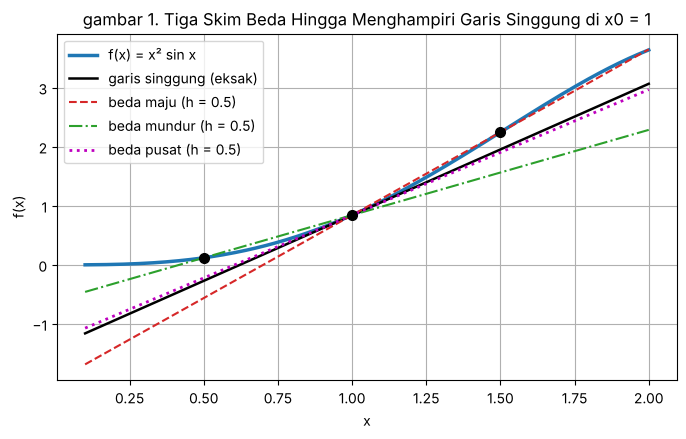

kemiringan maju   h = 0.5: 2.805785   (eksak 2.223244)
kemiringan mundur h = 0.5: 1.443229   (eksak 2.223244)
kemiringan pusat  h = 0.5: 2.124507   (eksak 2.223244)


In [4]:
# I.3 gambar 1. tiga garis potong terhadap garis singgung (h diperbesar agar terlihat)
hg = 0.5
xs = np.linspace(0.1, 2.0, 400)
fx = lambda x: x**2 * np.sin(x)
plt.figure(figsize=(8, 4.5))
plt.plot(xs, fx(xs), color="tab:blue", lw=2.5, label="f(x) = x² sin x")
plt.plot(xs, f(x0) + eksak * (xs - x0), color="k", lw=1.8, label="garis singgung (eksak)")
plt.plot(xs, f(x0) + beda_maju(f, x0, hg) * (xs - x0), "--", color="tab:red", label="beda maju (h = 0.5)")
plt.plot(xs, f(x0) + beda_mundur(f, x0, hg) * (xs - x0), "-.", color="tab:green", label="beda mundur (h = 0.5)")
plt.plot(xs, f(x0) + beda_pusat(f, x0, hg) * (xs - x0), ":", color="m", lw=2, label="beda pusat (h = 0.5)")
plt.plot([x0 - hg, x0, x0 + hg], [f(x0 - hg), f(x0), f(x0 + hg)], "ko", ms=7)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("gambar 1. Tiga Skim Beda Hingga Menghampiri Garis Singgung di x0 = 1")
plt.legend()
plt.grid(True)
plt.show()
for nama, skim in [("maju", beda_maju), ("mundur", beda_mundur), ("pusat", beda_pusat)]:
    print(f"kemiringan {nama:<6} h = 0.5: {skim(f, x0, hg):.6f}   (eksak {eksak:.6f})")

### lesson learnt task I

1. dengan h = 0.1, beda maju memberi 2.3688992 (galat relatif 6.55 persen) dan beda mundur 2.0697619 (6.90 persen). tanda galatnya berlawanan, +1.4565e-01 dan -1.5348e-01, karena suku utama galat dari deret Taylor adalah +h/2 f''(x0) untuk beda maju dan -h/2 f''(x0) untuk beda mundur. f''(1) = 3.0027 bernilai positif (fungsi cembung di x0 = 1), sehingga beda maju overestimate dan beda mundur underestimate. besarnya hampir sama, sekitar 1.50e-01 sesuai prediksi h/2 f''. selisih kecil di antara keduanya berasal dari suku berikutnya h^2/6 f'''(1) = -3.91e-03 yang tandanya sama untuk kedua skim

2. rata-rata beda maju dan mundur adalah 2.2193305443803775, sedangkan beda pusat 2.2193305443803770. selisihnya 4.44e-16, sebesar pembulatan saja. secara aljabar (1/2)[(f(x0+h) - f(x0))/h + (f(x0) - f(x0-h))/h] = (f(x0+h) - f(x0-h))/(2h), karena f(x0) saling menghapus. suku galat +h/2 f'' dan -h/2 f'' ikut saling menghapus, sehingga yang tersisa suku orde h^2. galat beda pusat -3.9137e-03 hampir sama dengan prediksi h^2/6 f'''(1) = -3.9122e-03

3. galat beda pusat 37.2 kali lebih kecil dari beda maju dan 39.2 kali lebih kecil dari beda mundur, padahal ketiganya hanya memakai dua evaluasi fungsi. rasio ini cocok dengan perbandingan suku utama (h/2 f'')/(h^2/6 f''') = 3 f''/(h f''') sekitar 38 pada h = 0.1, jadi selisih orde O(h) dan O(h^2) yang menjelaskannya. gambar 1 memakai h = 0.5 agar perbedaannya terlihat: kemiringan beda maju 2.806 berada di atas garis singgung 2.223, beda mundur 1.443 di bawahnya, dan beda pusat 2.125 paling dekat

---
# Task II: Trade-off Galat Pemotongan dan Pembulatan

h dikecilkan dari 1e-1 sampai 1e-10. kalau hanya galat pemotongan yang berperan, galat harus terus turun. tabel dan kurva log-log di bawah memeriksa apakah itu benar

In [5]:
# II.1 galat relatif beda maju dan beda pusat untuk h per dekade
print(f"{'h':>7}{'Er maju (%)':>15}{'Er pusat (%)':>15}{'rasio maju':>12}{'rasio pusat':>13}")
sebelum = None
for h in [10.0**-k for k in range(1, 11)]:
    Em = abs(beda_maju(f, x0, h) - eksak) / eksak * 100
    Ep = abs(beda_pusat(f, x0, h) - eksak) / eksak * 100
    rasio = "" if sebelum is None else f"{sebelum[0] / Em:>12.2f}{sebelum[1] / Ep:>13.2f}"
    print(f"{h:>7.0e}{Em:>15.6e}{Ep:>15.6e}{rasio}")
    sebelum = (Em, Ep)

      h    Er maju (%)   Er pusat (%)  rasio maju  rasio pusat
  1e-01   6.551459e+00   1.760369e-01
  1e-02   6.735073e-01   1.759683e-03        9.73       100.04
  1e-03   6.751162e-02   1.759677e-05        9.98       100.00
  1e-04   6.752749e-03   1.759835e-07       10.00        99.99
  1e-05   6.752913e-04   1.728102e-09       10.00       101.84
  1e-06   6.752368e-05   1.268122e-09       10.00         1.36
  1e-07   6.785219e-06   6.222438e-09        9.95         0.20
  1e-08   9.365170e-08   1.560336e-07       72.45         0.04
  1e-09   9.082324e-06   1.591764e-06        0.01         0.10
  1e-10   2.087992e-05   2.087992e-05        0.43         0.08


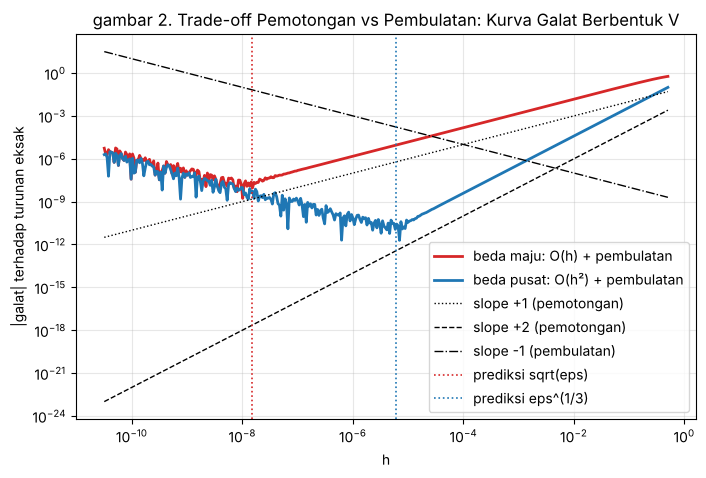

In [6]:
# II.2 gambar 2. kurva galat V pada kisi logaritmik rapat
hs = np.logspace(-10.5, -0.3, 400)
Em = [abs(beda_maju(f, x0, t) - eksak) for t in hs]
Ep = [abs(beda_pusat(f, x0, t) - eksak) for t in hs]
plt.figure(figsize=(8, 5))
plt.loglog(hs, Em, color="tab:red", lw=2, label="beda maju: O(h) + pembulatan")
plt.loglog(hs, Ep, color="tab:blue", lw=2, label="beda pusat: O(h²) + pembulatan")
plt.loglog(hs, 0.1 * hs, ":", color="k", lw=1, label="slope +1 (pemotongan)")
plt.loglog(hs, 0.01 * hs**2, "--", color="k", lw=1, label="slope +2 (pemotongan)")
plt.loglog(hs, 1e-9 / hs, "-.", color="k", lw=1, label="slope -1 (pembulatan)")
eps = np.finfo(float).eps
plt.axvline(eps**0.5, color="tab:red", ls=":", lw=1.2, label="prediksi sqrt(eps)")
plt.axvline(eps**(1 / 3), color="tab:blue", ls=":", lw=1.2, label="prediksi eps^(1/3)")
plt.xlabel("h")
plt.ylabel("|galat| terhadap turunan eksak")
plt.title("gambar 2. Trade-off Pemotongan vs Pembulatan: Kurva Galat Berbentuk V")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [7]:
# II.3 h optimal eksperimen dibanding prediksi teoretis
hs = np.logspace(-10, -0.5, 200)
Em = [abs(beda_maju(f, x0, t) - eksak) for t in hs]
Ep = [abs(beda_pusat(f, x0, t) - eksak) for t in hs]
eps = np.finfo(float).eps
print(f"epsilon mesin    = {eps:.4e}")
print(f"h* maju  : {hs[np.argmin(Em)]:.4e}   galat minimum {min(Em):.3e}   prediksi sqrt(eps) = {eps**0.5:.4e}")
print(f"h* pusat : {hs[np.argmin(Ep)]:.4e}   galat minimum {min(Ep):.3e}   prediksi eps^(1/3) = {eps**(1/3):.4e}")

epsilon mesin    = 2.2204e-16
h* maju  : 1.0116e-08   galat minimum 2.548e-10   prediksi sqrt(eps) = 1.4901e-08
h* pusat : 5.3227e-06   galat minimum 2.793e-12   prediksi eps^(1/3) = 6.0555e-06


In [8]:
# II.4 melacak pembilang beda pusat: digit yang tersisa setelah pengurangan
print(f"{'h':>7}{'f(x0+h)':>22}{'f(x0-h)':>22}{'pembilang':>13}{'digit sisa':>12}")
for h in [1e-2, 1e-5, 1e-8, 1e-11, 1e-13]:
    a, b = f(x0 + h), f(x0 - h)
    pembilang = a - b
    # f(x) sekitar 0.84 menyimpan sekitar 16 digit; pembilang kecil berarti digit depan sudah saling hapus
    sisa = 16 + math.log10(abs(pembilang) / abs(f(x0)))
    print(f"{h:>7.0e}{a:>22.16f}{b:>22.16f}{pembilang:>13.4e}{sisa:>12.1f}")

      h               f(x0+h)               f(x0-h)    pembilang  digit sisa
  1e-02    0.8638531646948373    0.8193890616263702   4.4464e-02        14.7
  1e-05    0.8414932174007851    0.8414487525152762   4.4465e-05        11.7
  1e-08    0.8414710070403393    0.8414709625754538   4.4465e-08         8.7
  1e-11    0.8414709848301289    0.8414709847856641   4.4465e-11         5.7
  1e-13    0.8414709848081187    0.8414709848076741   4.4453e-13         3.7


### lesson learnt task II

1. tabel II.1 sama dengan Tabel 4 modul. galat beda maju turun sekitar 10 kali per dekade sampai h = 1e-7, dan galat beda pusat turun sekitar 100 kali per dekade sampai h = 1e-5. setelah itu arahnya berbalik: beda pusat naik dari 1.27e-09 persen (h = 1e-6) ke 2.09e-05 persen (h = 1e-10), dan beda maju naik dari 9.37e-08 persen (h = 1e-8) ke 2.09e-05 persen. pada h = 1e-10 kedua skim memberi galat yang sama persis, 2.087992e-05 persen, tanda bahwa hasilnya sudah ditentukan pembulatan dan bukan rumus skim. tabel II.4 menunjukkan sebabnya: pembilang f(x0+h) - f(x0-h) mengecil sebanding h, sedangkan tiap nilai fungsi tetap membawa galat pembulatan sekitar eps |f| = 1.9e-16. digit bena yang tersisa setelah pengurangan turun dari 14.7 (h = 1e-2) ke 8.7 (h = 1e-8) lalu 3.7 (h = 1e-13), dan pada h = 1e-13 pembilangnya sudah meleset di digit keempat (4.4453e-13, seharusnya sekitar 4.4465e-13). ini catastrophic cancellation dari Modul 1, lalu galatnya diperbesar lagi saat dibagi h yang kecil

2. h* eksperimen pada kisi 200 titik adalah 1.01e-08 untuk beda maju dan 5.32e-06 untuk beda pusat, dibanding prediksi sqrt(eps) = 1.49e-08 dan eps^(1/3) = 6.06e-06. keduanya cocok dalam satu ordo besaran. modul melaporkan 5.94e-06 untuk beda pusat dengan kisi yang sama. dugaan saya perbedaannya muncul karena dasar kurva V di gambar 2 bergerigi oleh galat pembulatan, sehingga beberapa h di sekitar minimum punya galat yang hampir sama dan argmin bisa jatuh ke titik kisi lain pada versi NumPy atau library matematika yang berbeda. angka pada tabel II.1 sendiri sama persis dengan modul

3. galat terkecil yang bisa dicapai beda maju adalah 2.55e-10, sedangkan beda pusat 2.79e-12. aturan praktis yang saya ambil: h tidak dibuat sekecil mungkin, tetapi dipilih di sekitar h*, yaitu orde 1e-8 untuk skim orde satu dan orde 1e-6 sampai 1e-5 untuk beda pusat pada presisi ganda. untuk x0 yang jauh dari 1, jarak antar bilangan floating point di sekitar x0 ikut membesar (Modul 1), sehingga dugaan saya h juga perlu diskalakan dengan |x0|

---
# Task III: Turunan dari Data Tabular

rumus fungsi dianggap tidak diketahui. data pertama adalah posisi sensor tiap 0.1 detik (dibangkitkan dari s = 45t^2), data kedua adalah tabel tujuh titik dari Munir (2021, Contoh 7.1)

In [9]:
# III.1 kecepatan dari data posisi sensor
t = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
s = np.array([0.0, 0.45, 1.8, 4.05, 7.2, 11.25])    # posisi (cm)
dt = 0.1

def kecepatan(s, dt):
    """beda maju di titik pertama, beda mundur di titik terakhir, beda pusat di interior."""
    n = len(s)
    v = np.empty(n)
    v[0] = (s[1] - s[0]) / dt
    v[-1] = (s[-1] - s[-2]) / dt
    v[1:-1] = (s[2:] - s[:-2]) / (2 * dt)
    return v

v = kecepatan(s, dt)
skim = ["maju"] + ["pusat"] * (len(t) - 2) + ["mundur"]
print(f"{'t (s)':>6}{'skim':>8}{'v taksiran':>12}{'v eksak':>9}{'galat':>9}")
for ti, sk, vi in zip(t, skim, v):
    print(f"{ti:>6.1f}{sk:>8}{vi:>12.2f}{90 * ti:>9.1f}{abs(vi - 90 * ti):>9.2f}")

 t (s)    skim  v taksiran  v eksak    galat
   0.0    maju        4.50      0.0     4.50
   0.1   pusat        9.00      9.0     0.00
   0.2   pusat       18.00     18.0     0.00
   0.3   pusat       27.00     27.0     0.00
   0.4   pusat       36.00     36.0     0.00
   0.5  mundur       40.50     45.0     4.50


In [10]:
# III.2 percepatan interior dengan formula pusat turunan kedua
a = (s[2:] - 2 * s[1:-1] + s[:-2]) / dt**2
for ti, ai in zip(t[1:-1], a):
    print(f"t = {ti:.1f}: a = {ai:.2f} cm/s^2   (eksak 90.0)")
print()
# perbaikan titik ujung dengan beda satu sisi tiga titik orde dua
v0_3t = (-3 * s[0] + 4 * s[1] - s[2]) / (2 * dt)
v5_3t = (3 * s[-1] - 4 * s[-2] + s[-3]) / (2 * dt)
print(f"v(0.0) beda maju 3 titik  = {v0_3t:.4f} cm/s   (eksak 0.0)")
print(f"v(0.5) beda mundur 3 titik = {v5_3t:.4f} cm/s   (eksak 45.0)")

t = 0.1: a = 90.00 cm/s^2   (eksak 90.0)
t = 0.2: a = 90.00 cm/s^2   (eksak 90.0)
t = 0.3: a = 90.00 cm/s^2   (eksak 90.0)
t = 0.4: a = 90.00 cm/s^2   (eksak 90.0)

v(0.0) beda maju 3 titik  = 0.0000 cm/s   (eksak 0.0)
v(0.5) beda mundur 3 titik = 45.0000 cm/s   (eksak 45.0)


In [11]:
# III.3 tabel klasik Munir (2021, Contoh 7.1)
xb = np.array([1.3, 1.5, 1.7, 1.9, 2.1, 2.3, 2.5])
fb = np.array([3.669, 4.482, 5.474, 6.686, 8.166, 9.974, 12.182])
hb = 0.2

f17_oh2 = (fb[3] - fb[1]) / (2 * hb)
f17_oh4 = (-fb[4] + 8 * fb[3] - 8 * fb[1] + fb[0]) / (12 * hb)
f13_maju = (fb[1] - fb[0]) / hb
f25_mundur = (fb[6] - fb[5]) / hb

print("cek dugaan f = e^x:", [f"{math.exp(x):.3f}" for x in xb])
print()
print(f"{'pertanyaan':<12}{'rumus':<18}{'tabel':>8}{'eksak e^x':>11}{'galat':>9}")
for q, rumus, nilai, x in [("f'(1.7)", "pusat O(h^2)", f17_oh2, 1.7), ("f'(1.7)", "pusat O(h^4)", f17_oh4, 1.7),
                           ("f'(1.3)", "maju O(h)", f13_maju, 1.3), ("f'(2.5)", "mundur O(h)", f25_mundur, 2.5)]:
    print(f"{q:<12}{rumus:<18}{nilai:>8.3f}{math.exp(x):>11.4f}{abs(nilai - math.exp(x)):>9.4f}")

cek dugaan f = e^x: ['3.669', '4.482', '5.474', '6.686', '8.166', '9.974', '12.182']

pertanyaan  rumus                tabel  eksak e^x    galat
f'(1.7)     pusat O(h^2)         5.510     5.4739   0.0361
f'(1.7)     pusat O(h^4)         5.473     5.4739   0.0010
f'(1.3)     maju O(h)            4.065     3.6693   0.3957
f'(2.5)     mundur O(h)         11.040    12.1825   1.1425


In [12]:
# III.4 batas akurasi karena data dibulatkan 3 desimal: rumus O(h^4) pada data eksak dan data tabel
fb_eksak = np.exp(xb)
for nama, data in [("data tabel 3 desimal", fb), ("data eksak e^x", fb_eksak)]:
    d2 = (data[3] - data[1]) / (2 * hb)
    d4 = (-data[4] + 8 * data[3] - 8 * data[1] + data[0]) / (12 * hb)
    print(f"{nama:<22} O(h^2) galat {abs(d2 - math.exp(1.7)):.2e}   O(h^4) galat {abs(d4 - math.exp(1.7)):.2e}")
print(f"galat bulat data maks = {np.max(np.abs(fb - fb_eksak)):.2e}")
print(f"perkiraan derau pada O(h^4): (1+8+8+1) * 5e-4 / (12 * 0.2) = {18 * 5e-4 / (12 * hb):.2e}")

data tabel 3 desimal   O(h^2) galat 3.61e-02   O(h^4) galat 1.03e-03
data eksak e^x         O(h^2) galat 3.66e-02   O(h^4) galat 2.93e-04
galat bulat data maks = 4.94e-04
perkiraan derau pada O(h^4): (1+8+8+1) * 5e-4 / (12 * 0.2) = 3.75e-03


### lesson learnt task III

1. kecepatan interior pada t = 0.1 sampai 0.4 tepat 9, 18, 27, dan 36 cm/s, dan percepatan interior tepat 90.00 cm/s^2. ini bukan kebetulan: data dibangkitkan dari s = 45t^2, dan galat beda pusat sebanding f''' yang bernilai nol untuk polinom derajat dua. rumusnya sama dengan kemiringan parabola interpolasi di titik tengah (Modul 5). sebaliknya, kedua titik ujung meleset 4.50 cm/s: v(0) tertaksir 4.50 (eksak 0) dan v(0.5) tertaksir 40.50 (eksak 45). titik ujung hanya punya satu tetangga, sehingga terpaksa memakai skim satu sisi O(h) dengan suku galat h/2 f'' = 0.05 x 90 = 4.5, persis galat yang muncul

2. tiga cara memperbaiki titik ujung pada sistem instrumentasi: (1) memakai beda satu sisi tiga titik berorde O(h^2), yang pada data ini memberi v(0) = 0.0000 dan v(0.5) = 45.0000, sama dengan eksak; (2) merekam satu titik ekstra di luar rentang yang dilaporkan, sehingga titik ujung lama berubah menjadi titik interior; (3) memfilter derau sebelum diturunkan, karena pada data sensor nyata beda hingga memperbesar derau. data di sini bebas derau, jadi cara ketiga belum terlihat efeknya di notebook ini

3. tabel Munir ternyata e^x yang dibulatkan tiga desimal (cek dugaan di III.3 cocok di ketujuh titik). pada f'(1.7), beda pusat O(h^2) meleset 0.0361 dan O(h^4) meleset 0.0010, jadi menaikkan orde masih berguna di sini. titik ujung tetap paling buruk: beda maju meleset 0.3957 dan beda mundur 1.1425. sel III.4 memisahkan dua sumber galat. dengan data e^x eksak, rumus O(h^4) meleset 2.93e-04, sedangkan dengan data tabel meleset 1.03e-03, sehingga sebagian besar galatnya berasal dari pembulatan data (paling besar 4.94e-04 per titik), bukan dari rumusnya. rumus O(h^2) hampir tidak terpengaruh (3.61e-02 dibanding 3.66e-02) karena galat pemotongannya masih jauh lebih besar. kesimpulannya, menaikkan orde rumus hanya membantu selama galat pemotongan masih lebih besar dari galat data

---
# Task IV: Turunan Kedua

formula pusat (f(x0+h) - 2f(x0) + f(x0-h))/h^2 diuji pada f(x) = x^3 di x0 = 1 (eksak 6). rentang h diperluas sampai 1e-8 untuk melihat ke mana galat pembulatan membawa hasilnya

In [13]:
# IV.1 sensitivitas h pada turunan kedua f(x) = x^3
def turunan_kedua(f, x, h):
    return (f(x + h) - 2 * f(x) + f(x - h)) / h**2

kubik = lambda x: x**3
print(f"{'h':>7}{'f-dua hampiran':>18}{'Er (%)':>12}{'rasio':>8}")
sebelum = None
for h in [10.0**-k for k in range(1, 9)]:
    ap = turunan_kedua(kubik, 1.0, h)
    er = abs(ap - 6) / 6 * 100
    rasio = "" if sebelum is None or sebelum == 0 else f"{er / sebelum:>8.0f}"
    print(f"{h:>7.0e}{ap:>18.10f}{er:>12.3e}{rasio}")
    sebelum = er

      h    f-dua hampiran      Er (%)   rasio
  1e-01      6.0000000000   8.142e-13
  1e-02      6.0000000000   2.599e-11      32
  1e-03      5.9999999997   4.526e-09     174
  1e-04      5.9999999857   2.377e-07      53
  1e-05      6.0000027169   4.528e-05     191
  1e-06      5.9997562474   4.063e-03      90
  1e-07      6.0285110237   4.752e-01     117
  1e-08      2.2204460493   6.299e+01     133


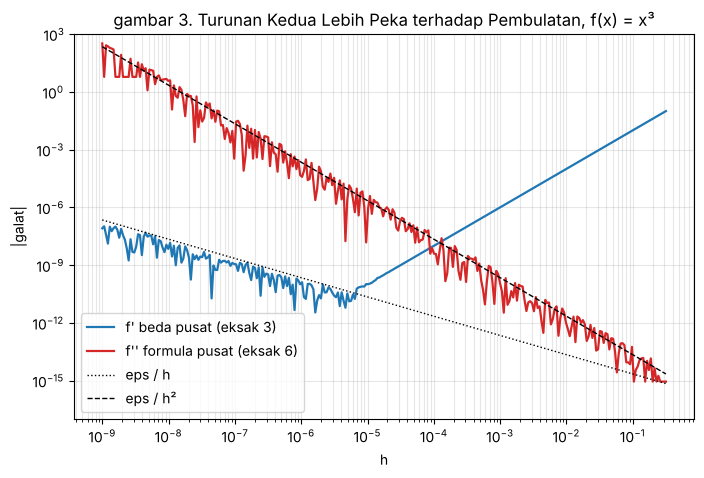

h* turunan kedua pada fungsi umum ~ eps^(1/4) = 1.22e-04


In [14]:
# IV.2 gambar 3. galat turunan pertama dan kedua pada kisi h yang sama
hs = np.logspace(-9, -0.5, 300)
E1 = [abs(beda_pusat(kubik, 1.0, t) - 3) + 1e-18 for t in hs]
E2 = [abs(turunan_kedua(kubik, 1.0, t) - 6) + 1e-18 for t in hs]
eps = np.finfo(float).eps
plt.figure(figsize=(8, 5))
plt.loglog(hs, E1, color="tab:blue", lw=1.6, label="f' beda pusat (eksak 3)")
plt.loglog(hs, E2, color="tab:red", lw=1.6, label="f'' formula pusat (eksak 6)")
plt.loglog(hs, eps / hs, ":", color="k", lw=1, label="eps / h")
plt.loglog(hs, eps / hs**2, "--", color="k", lw=1, label="eps / h²")
plt.ylim(1e-17, 1e3)
plt.xlabel("h")
plt.ylabel("|galat|")
plt.title("gambar 3. Turunan Kedua Lebih Peka terhadap Pembulatan, f(x) = x³")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()
print(f"h* turunan kedua pada fungsi umum ~ eps^(1/4) = {eps**0.25:.2e}")

In [15]:
# IV.3 pembanding fungsi yang bukan polinom: f(x) = sin x di x0 = 1, eksak -sin 1
print(f"{'h':>7}{'Er f-dua (%)':>14}")
for h in [10.0**-k for k in range(1, 8)]:
    ap = turunan_kedua(math.sin, 1.0, h)
    print(f"{h:>7.0e}{abs(ap + math.sin(1)) / math.sin(1) * 100:>14.3e}")

      h  Er f-dua (%)
  1e-01     8.331e-02
  1e-02     8.333e-04
  1e-03     8.329e-06
  1e-04     3.595e-07
  1e-05     9.008e-05
  1e-06     9.278e-03
  1e-07     1.046e+00


### lesson learnt task IV

1. untuk f(x) = x^3, galat pemotongan formula pusat sebanding h^2/12 f''''(x), dan f'''' = 0, sehingga hasilnya seharusnya tepat 6. galat 8.142e-13 persen pada h = 0.1 (sama dengan Tabel 8 modul) murni berasal dari pembulatan. perkiraan kasarnya eps |f| / h^2 = 2.2e-16 / 0.01 = 2.2e-14, atau 3.7e-13 persen terhadap 6, satu ordo dengan angka yang terukur

2. memperkecil h 10 kali memperbesar galat dengan rasio 32, 174, 53, 191, 90, dan 117 per dekade. rasionya tidak tepat 100 karena galat pembulatan bertanda acak, tetapi dari h = 1e-1 ke h = 1e-6 galatnya naik dari 8.14e-13 ke 4.06e-03 persen, rata-rata sekitar 87 kali per dekade, dekat dengan pola eps/h^2. pada h = 1e-8 hasilnya 2.2204460493, meleset 63 persen. angka itu sama dengan eps/h^2 = 2.22e-16 / 1e-16: pembilang f(1+h) - 2f(1) + f(1-h) tersisa satu satuan pembulatan saja, lalu dibagi 1e-16

3. gambar 3 membandingkan kedua turunan pada fungsi yang sama. galat turunan pertama beda pusat di sisi kiri mengikuti eps/h, sedangkan galat turunan kedua mengikuti eps/h^2 di seluruh rentang h, sehingga pada h = 1e-6 galat turunan kedua (2.44e-04) sudah sekitar 3 juta kali galat turunan pertama (8.03e-11). pada sin x (IV.3), yang galat pemotongannya tidak nol, galat terkecil turunan kedua ada di h = 1e-4 (3.60e-07 persen), dekat dengan eps^(1/4) = 1.22e-04. jadi turunan kedua paling butuh kehati-hatian memilih h, dan h optimalnya jauh lebih besar daripada beda pusat turunan pertama (sekitar 6e-06)

---
# Kesimpulan Praktikum

| skim | titik yang dipakai | orde galat | hasil di notebook | h optimal |
|---|---|---|---|---|
| beda maju | x0, x0+h | O(h) | Er 6.55% pada x^2 sin x, h = 0.1 | sekitar 1e-8 |
| beda mundur | x0-h, x0 | O(h) | Er 6.90% | sekitar 1e-8 |
| beda pusat | x0-h, x0+h | O(h^2) | Er 0.176% | sekitar 5e-6 |
| beda maju tiga titik | x0, x0+h, x0+2h | O(h^2) | galat 0.0518 pada f'(1.3) tabel Munir, beda maju biasa 0.3957 | |
| beda pusat empat titik | x0 +- h, x0 +- 2h | O(h^4) | galat 0.0010 pada f'(1.7), pusat biasa 0.0361 | |
| turunan kedua pusat | x0-h, x0, x0+h | O(h^2) | Er 8.33e-02% pada cos x, h = 0.1 | sekitar 1e-4 |
| Richardson | D(h), D(2h) | O(h^4) | galat 3.91e-03 turun ke 6.13e-06 | |

temuan dari keempat task:

1. beda pusat adalah rata-rata beda maju dan mundur (selisih 4.44e-16), sehingga suku galat orde h saling menghapus. pada h = 0.1 hasilnya 37 sampai 39 kali lebih akurat dengan dua evaluasi fungsi yang sama
2. h yang makin kecil tidak selalu lebih baik. kurva galat berbentuk V dengan dasar di 1.01e-08 untuk beda maju dan 5.32e-06 untuk beda pusat, satu ordo dengan prediksi sqrt(eps) dan eps^(1/3). di kiri dasar itu catastrophic cancellation dari Modul 1 yang menentukan galat
3. pada data tabular, titik interior bisa tepat (galat 0 pada data s = 45t^2) sementara titik ujung meleset 4.5 cm/s. beda satu sisi tiga titik memperbaiki ujung tanpa data tambahan. pada data yang sudah dibulatkan, rumus orde tinggi dibatasi oleh galat data (1.03e-03 dibanding 2.93e-04 pada data eksak)
4. turunan kedua paling peka terhadap pembulatan karena dibagi h^2. pada x^3 galatnya naik dari 8.14e-13 persen ke 63 persen ketika h turun dari 1e-1 ke 1e-8

---
---
# BAGIAN III.8 - Tugas Praktikum

## Soal 1. Turunan eksponensial

f'(1) untuk f(x) = e^x (eksak e) dengan beda maju dan beda pusat, h = 0.1 dan h = 0.01. bandingkan perbaikan akurasi kedua skim ketika h diperkecil 10 kali

In [16]:
# Soal 1. turunan e^x di x = 1
e = math.e
print(f"{'h':>6}{'maju':>12}{'Er maju':>10}{'pusat':>12}{'Er pusat':>11}")
hasil1 = {}
for h in [0.1, 0.01]:
    dm, dp = beda_maju(math.exp, 1.0, h), beda_pusat(math.exp, 1.0, h)
    hasil1[h] = (abs(dm - e) / e * 100, abs(dp - e) / e * 100)
    print(f"{h:>6}{dm:>12.7f}{hasil1[h][0]:>9.3f}%{dp:>12.7f}{hasil1[h][1]:>10.5f}%")
print(f"\nfaktor perbaikan maju  = {hasil1[0.1][0] / hasil1[0.01][0]:.1f}")
print(f"faktor perbaikan pusat = {hasil1[0.1][1] / hasil1[0.01][1]:.1f}")

     h        maju   Er maju       pusat   Er pusat
   0.1   2.8588420    5.171%   2.7228146   0.16675%
  0.01   2.7319187    0.502%   2.7183271   0.00167%

faktor perbaikan maju  = 10.3
faktor perbaikan pusat = 100.0


### jawaban soal 1

| h | beda maju | galat relatif | beda pusat | galat relatif |
|---|---|---|---|---|
| 0.1 | 2.8588420 | 5.171% | 2.7228146 | 0.16675% |
| 0.01 | 2.7319187 | 0.502% | 2.7183271 | 0.00167% |

keempat galat sama dengan petunjuk. ketika h diperkecil 10 kali, galat beda maju turun 10.3 kali (orde satu) dan galat beda pusat turun 100.0 kali (orde dua). faktor beda maju sedikit di atas 10 karena galatnya h/2 e + h^2/6 e + ..., dan suku kedua masih terasa pada h = 0.1: (0.05 + 0.001667)/(0.005 + 0.0000167) = 10.30. dengan biaya dua evaluasi fungsi yang sama, beda pusat pada h = 0.1 sudah lebih akurat daripada beda maju pada h = 0.01.

## Soal 2. Kecepatan dari data pengukuran

t = [0, 1, 2, 3, 4] s, s = [0, 2.1, 8.3, 18.1, 33.2] m. kecepatan pada t = 1, 2, 3 dengan beda pusat, t = 0 beda maju, dan t = 4 beda mundur

In [17]:
# Soal 2. kecepatan dari data posisi (meter)
t2 = np.array([0.0, 1.0, 2.0, 3.0, 4.0])
s2 = np.array([0.0, 2.1, 8.3, 18.1, 33.2])
v2 = kecepatan(s2, 1.0)
skim2 = ["maju", "pusat", "pusat", "pusat", "mundur"]
for ti, sk, vi in zip(t2, skim2, v2):
    print(f"t = {ti:.0f} s  {sk:<7} v = {vi:.2f} m/s")
print()
# pembanding: beda satu sisi tiga titik orde dua di kedua ujung
print(f"v(0) beda maju 3 titik   = {(-3 * s2[0] + 4 * s2[1] - s2[2]) / 2:.2f} m/s")
print(f"v(4) beda mundur 3 titik = {(3 * s2[4] - 4 * s2[3] + s2[2]) / 2:.2f} m/s")
print()
# percepatan interior sebagai gambaran kelengkungan data
a2 = (s2[2:] - 2 * s2[1:-1] + s2[:-2]) / 1.0**2
print("percepatan interior:", a2)

t = 0 s  maju    v = 2.10 m/s
t = 1 s  pusat   v = 4.15 m/s
t = 2 s  pusat   v = 8.00 m/s
t = 3 s  pusat   v = 12.45 m/s
t = 4 s  mundur  v = 15.10 m/s

v(0) beda maju 3 titik   = 0.05 m/s
v(4) beda mundur 3 titik = 17.75 m/s

percepatan interior: [4.1 3.6 5.3]


### jawaban soal 2

| t (s) | skim | v (m/s) |
|---|---|---|
| 0 | maju | 2.10 |
| 1 | pusat | 4.15 |
| 2 | pusat | 8.00 |
| 3 | pusat | 12.45 |
| 4 | mundur | 15.10 |

hasilnya sama dengan petunjuk. titik ujung hanya punya tetangga di satu sisi, sehingga memakai skim O(h) dengan suku galat h/2 f''. di sini h = 1 s cukup besar dan percepatan interior data ini 4.1, 3.6, dan 5.3 m/s^2, jadi galat ujung bisa mencapai sekitar 0.5 x 1 x 4 = 2 m/s. di titik interior suku itu saling menghapus dan yang tersisa h^2/6 f'''.

fungsi aslinya tidak diketahui, jadi galat sebenarnya tidak bisa dihitung. sebagai gantinya saya membandingkan dengan beda satu sisi tiga titik berorde O(h^2): v(0) = 0.05 m/s dan v(4) = 17.75 m/s. selisihnya terhadap hasil O(h) adalah 2.05 dan 2.65 m/s, sesuai perkiraan h/2 f'' di atas. angka ini menunjukkan seberapa besar ketidakpastian kecepatan di titik ujung.

## Soal 3. Pencarian h optimal

f(x) = e^x di x0 = 1, h optimal beda pusat pada kisi `np.logspace(-9, -0.5, 200)` dibanding prediksi eps^(1/3)

In [18]:
# Soal 3. h optimal beda pusat untuk e^x
hs = np.logspace(-9, -0.5, 200)
Ep = np.array([abs(beda_pusat(math.exp, 1.0, t) - e) for t in hs])
k = np.argmin(Ep)
print(f"h* eksperimen = {hs[k]:.4e}   galat {Ep[k]:.3e}")
print(f"prediksi eps^(1/3) = {eps**(1/3):.4e}")
print(f"prediksi (3 eps |f| / |f3|)^(1/3), untuk e^x |f| = |f3| = e: {(3 * eps)**(1/3):.4e}")
print()
print("lima kandidat h dengan galat terkecil:")
for j in np.argsort(Ep)[:5]:
    print(f"  h = {hs[j]:.4e}   galat = {Ep[j]:.3e}")
print()
print("kisi berbeda memberi h* berbeda:")
for n_kisi in [100, 200, 400, 1000]:
    hk = np.logspace(-9, -0.5, n_kisi)
    Ek = [abs(beda_pusat(math.exp, 1.0, t) - e) for t in hk]
    print(f"  {n_kisi:>4} titik: h* = {hk[int(np.argmin(Ek))]:.4e}")

h* eksperimen = 3.5093e-06   galat 9.712e-13
prediksi eps^(1/3) = 6.0555e-06
prediksi (3 eps |f| / |f3|)^(1/3), untuk e^x |f| = |f3| = e: 8.7335e-06

lima kandidat h dengan galat terkecil:
  h = 3.5093e-06   galat = 9.712e-13
  h = 4.7138e-06   galat = 2.740e-12
  h = 6.3315e-06   galat = 5.010e-12
  h = 3.1806e-06   galat = 5.105e-12
  h = 8.8560e-07   galat = 1.176e-11

kisi berbeda memberi h* berbeda:
   100 titik: h* = 1.8307e-06
   200 titik: h* = 3.5093e-06
   400 titik: h* = 5.8976e-06
  1000 titik: h* = 6.4835e-06


### jawaban soal 3

h* eksperimen pada kisi `np.logspace(-9, -0.5, 200)` adalah 3.51e-06 dengan galat 9.71e-13, sama dengan petunjuk. prediksi eps^(1/3) = 6.06e-06, jadi keduanya cocok dalam satu ordo besaran. bila konstanta fungsi ikut dihitung, h* = (3 eps |f| / |f'''|)^(1/3) = 8.73e-06 untuk e^x karena |f| = |f'''|.

posisi h* berpindah bila kisinya diubah: 1.83e-06 (100 titik), 3.51e-06 (200 titik), 5.90e-06 (400 titik), dan 6.48e-06 (1000 titik). penyebabnya terlihat pada lima kandidat terbaik: h dari 8.86e-07 sampai 6.33e-06 punya galat antara 9.7e-13 dan 1.2e-11. di dasar kurva V galat pemotongan dan galat pembulatan sama besar, dan galat pembulatan bertanda acak, sehingga titik mana yang kebetulan paling kecil tergantung letak titik kisi. h* sebaiknya dibaca sebagai ordo besaran, bukan angka pasti.

## Soal 4. Turunan kedua cos x

f''(1) untuk f(x) = cos x (eksak -cos 1) dengan formula pusat, h = 1e-1, 1e-2, 1e-3, lalu amati orde konvergensinya

In [19]:
# Soal 4. turunan kedua cos x di x = 1
eksak4 = -math.cos(1.0)
print(f"eksak f''(1) = {eksak4:.10f}")
sebelum = None
for h in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]:
    ap = turunan_kedua(math.cos, 1.0, h)
    er = abs(ap - eksak4) / abs(eksak4) * 100
    p = "" if sebelum is None else f"   orde teramati p = {math.log10(sebelum / er):.3f}"
    print(f"h = {h:.0e}: f'' = {ap:.10f}   Er = {er:.3e}%{p}")
    sebelum = er

eksak f''(1) = -0.5403023059
h = 1e-01: f'' = -0.5398522040   Er = 8.331e-02%
h = 1e-02: f'' = -0.5402978034   Er = 8.333e-04%   orde teramati p = 2.000
h = 1e-03: f'' = -0.5403022608   Er = 8.337e-06%   orde teramati p = 2.000
h = 1e-04: f'' = -0.5403023251   Er = 3.560e-06%   orde teramati p = 0.370
h = 1e-05: f'' = -0.5403044678   Er = 4.001e-04%   orde teramati p = -2.051


### jawaban soal 4

| h | f''(1) hampiran | galat relatif | orde teramati |
|---|---|---|---|
| 1e-1 | -0.5398522040 | 8.331e-02% | |
| 1e-2 | -0.5402978034 | 8.333e-04% | 2.000 |
| 1e-3 | -0.5403022608 | 8.337e-06% | 2.000 |

ketiga galat sama dengan petunjuk (8.33e-2, 8.33e-4, 8.34e-6 persen). galatnya turun 100 kali per dekade dan orde teramatinya 2.000, sesuai O(h^2). untuk cos x, suku galat h^2/12 f''''(x) dibagi f''(x) memberi tepat h^2/12 karena f'''' = cos x = -f''. pada h = 0.1 nilainya 0.01/12 = 8.33e-04, atau 8.33e-02 persen, cocok dengan baris pertama.

saya menambahkan h = 1e-4 dan 1e-5 untuk melihat batasnya. galat pada h = 1e-4 hanya turun ke 3.56e-06 persen (orde teramati 0.370), lalu naik ke 4.00e-04 persen pada h = 1e-5 (orde -2.051). penurunan teratur berhenti di sekitar h = 1e-4, sama dengan h optimal turunan kedua di Task IV.

## Soal 5. Tabel klasik Munir

f'(1.3) dengan beda maju tiga titik dibanding beda maju biasa, lalu f'(2.1) dengan beda pusat orde empat pada titik 1.7, 1.9, 2.3, 2.5

In [20]:
# Soal 5. rumus orde tinggi pada tabel Munir
f13_3t = (-3 * fb[0] + 4 * fb[1] - fb[2]) / (2 * hb)
f21_oh4 = (fb[2] - 8 * fb[3] + 8 * fb[5] - fb[6]) / (12 * hb)
f21_oh2 = (fb[5] - fb[3]) / (2 * hb)
print(f"f'(1.3) beda maju biasa   = {f13_maju:.4f}   galat {abs(f13_maju - math.exp(1.3)):.4f}")
print(f"f'(1.3) beda maju 3 titik = {f13_3t:.4f}   galat {abs(f13_3t - math.exp(1.3)):.4f}   eksak {math.exp(1.3):.4f}")
print()
print(f"f'(2.1) pusat O(h^2) = {f21_oh2:.4f}   galat {abs(f21_oh2 - math.exp(2.1)):.4f}")
print(f"f'(2.1) pusat O(h^4) = {f21_oh4:.4f}   galat {abs(f21_oh4 - math.exp(2.1)):.4f}   eksak {math.exp(2.1):.4f}")
print()
# pembanding: ekstrapolasi Richardson dari dua beda pusat O(h^2) di x = 2.1 (h = 0.2 dan 2h = 0.4)
D_h, D_2h = f21_oh2, (fb[6] - fb[2]) / (4 * hb)
print(f"Richardson D(h) + (D(h) - D(2h))/3 = {D_h + (D_h - D_2h) / 3:.4f}")

f'(1.3) beda maju biasa   = 4.0650   galat 0.3957
f'(1.3) beda maju 3 titik = 3.6175   galat 0.0518   eksak 3.6693

f'(2.1) pusat O(h^2) = 8.2200   galat 0.0538
f'(2.1) pusat O(h^4) = 8.1650   galat 0.0012   eksak 8.1662

Richardson D(h) + (D(h) - D(2h))/3 = 8.1650


### jawaban soal 5

| pertanyaan | rumus | hasil | eksak | galat |
|---|---|---|---|---|
| f'(1.3) | beda maju biasa O(h) | 4.0650 | 3.6693 | 0.3957 |
| f'(1.3) | beda maju tiga titik O(h^2) | 3.6175 | 3.6693 | 0.0518 |
| f'(2.1) | beda pusat O(h^2) | 8.2200 | 8.1662 | 0.0538 |
| f'(2.1) | beda pusat O(h^4) | 8.1650 | 8.1662 | 0.0012 |

hasilnya sama dengan petunjuk. beda maju tiga titik memangkas galat di titik ujung 7.6 kali tanpa data tambahan, hanya dengan memakai titik ketiga dari sisi yang sama. beda pusat orde empat memangkas galat di x = 2.1 sekitar 45 kali dibanding beda pusat biasa.

sebagai pembanding, saya menerapkan ekstrapolasi Richardson pada dua beda pusat di x = 2.1 dengan h = 0.2 dan 2h = 0.4. hasilnya 8.1650, sama dengan rumus O(h^4). bila diuraikan, D(h) + (D(h) - D(2h))/3 menghasilkan bobot (1, -8, 8, -1)/(12h) pada titik 1.7, 1.9, 2.3, 2.5, yaitu rumus beda pusat empat titik itu sendiri.

---
---
# BAGIAN III.9 - Soal Latihan HOTS: Pemrograman Gaya ICPC

tiap problem ditulis sebagai fungsi `solve_X(data)` yang menerima seluruh masukan sebagai string dan mengembalikan keluaran sebagai string. keluaran dicocokkan langsung dengan contoh pada modul, lalu ditambah beberapa uji di luar contoh. untuk dijalankan ala ICPC cukup `print(solve_X(sys.stdin.read()))`

## Problem A. Kecepatan Sensor [C4 Analisis, Modul 6]

n posisi dengan selang Δt. titik pertama beda maju, titik terakhir beda mundur, interior beda pusat, 6 desimal

In [21]:
# Problem A. Kecepatan Sensor
def solve_A(data):
    tok = data.split()
    n, dt = int(tok[0]), float(tok[1])
    s = np.array(tok[2:2 + n], dtype=float)       # dibaca sekali sebagai larik
    return "\n".join(f"{v:.6f}" for v in kecepatan(s, dt))

masukan_A = """5 0.5
0.0 1.2 5.1 11.4 19.8"""
harapan_A = "2.400000\n5.100000\n10.200000\n14.700000\n16.800000"
hasil_A = solve_A(masukan_A)
print(hasil_A)
print("cocok dengan contoh:", hasil_A == harapan_A)
print()
import time
n_besar = 1000
data_besar = f"{n_besar} 0.01\n" + " ".join(str(4.9 * (0.01 * i)**2) for i in range(n_besar))
mulai = time.perf_counter()
keluar = solve_A(data_besar).split()
print(f"uji n = 1000 (s = 4.9 t^2): v[500] = {keluar[500]} (eksak {9.8 * 5.0:.6f}), "
      f"v[0] = {keluar[0]}, waktu {1000 * (time.perf_counter() - mulai):.2f} ms")

2.400000
5.100000
10.200000
14.700000
16.800000
cocok dengan contoh: True

uji n = 1000 (s = 4.9 t^2): v[500] = 49.000000 (eksak 49.000000), v[0] = 0.049000, waktu 0.84 ms


### jawaban problem A

keluaran cocok dengan contoh. fungsi `kecepatan` dari Task III dipakai ulang. posisi dibaca sekali sebagai larik NumPy, lalu ketiga cabang dihitung dengan slicing tanpa perulangan Python.

uji n = 1000 dengan s = 4.9t^2 dan Δt = 0.01 memberi v[500] = 49.000000, sama dengan eksak 9.8 x 5. v[0] = 0.049000 padahal eksaknya 0, sama dengan suku galat h/2 f'' = 0.005 x 9.8. waktu eksekusinya di bawah 1 ms pada percobaan ini, tetapi angkanya berubah tiap eksekusi.

## Problem B. Tiga Skim untuk Menu Fungsi [C4 Analisis, Modul 6]

menu 1 = sin, 2 = cos, 3 = e^x, 4 = ln x. untuk tiap kasus keluarkan maju, mundur, pusat (6 desimal)

In [22]:
# Problem B. Tiga Skim untuk Menu Fungsi
menu = {1: math.sin, 2: math.cos, 3: math.exp, 4: math.log}
menu_d1 = {1: math.cos, 2: lambda x: -math.sin(x), 3: math.exp, 4: lambda x: 1 / x}

def solve_B(data):
    tok = data.split()
    keluar = []
    for i in range(int(tok[0])):
        k, x0, h = int(tok[1 + 3 * i]), float(tok[2 + 3 * i]), float(tok[3 + 3 * i])
        g = menu[k]
        keluar.append(" ".join(f"{d:.6f}" for d in (beda_maju(g, x0, h), beda_mundur(g, x0, h), beda_pusat(g, x0, h))))
    return "\n".join(keluar)

masukan_B = """2
1 1.0 0.1
4 2.0 0.01"""
harapan_B = "0.497364 0.581441 0.539402\n0.498754 0.501254 0.500004"
hasil_B = solve_B(masukan_B)
print(hasil_B)
print("cocok dengan contoh:", hasil_B == harapan_B)
print()
print("ln x di x0 = 2, galat beda pusat terhadap 0.5:")
for h in [1e-2, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12]:
    print(f"  h = {h:.0e}: galat = {abs(beda_pusat(math.log, 2.0, h) - 0.5):.3e}")

0.497364 0.581441 0.539402
0.498754 0.501254 0.500004
cocok dengan contoh: True

ln x di x0 = 2, galat beda pusat terhadap 0.5:
  h = 1e-02: galat = 4.167e-06
  h = 1e-04: galat = 4.168e-10
  h = 1e-06: galat = 1.438e-11
  h = 1e-08: galat = 3.039e-09
  h = 1e-10: galat = 4.137e-08
  h = 1e-12: galat = 4.445e-05


### jawaban problem B

kedua baris cocok dengan contoh. menu fungsi disimpan dalam dictionary, dan ketiga skim dari Task I dipakai apa adanya.

untuk ln x di x0 = 2, galat beda pusat terhadap 0.5 adalah 4.17e-06 pada h = 0.01, sesuai petunjuk. petunjuk modul meminta mengulang dengan h = 1e-6 dan menjelaskan mengapa hasilnya memburuk, tetapi pada percobaan saya hasilnya justru membaik: galatnya 1.44e-11, lebih kecil dari 4.17e-10 pada h = 1e-4. alasannya, 1e-6 masih dekat h* beda pusat (sekitar 6e-06). hasil baru memburuk setelah h melewati h* lebih jauh: 3.04e-09 pada h = 1e-8, 4.14e-08 pada h = 1e-10, dan 4.45e-05 pada h = 1e-12.

## Problem C. Orde Teramati [C5 Evaluasi, Modul 1 + Modul 6]

p = log2(E1/E2) dari galat pada h dan h/2, 3 desimal

In [23]:
# Problem C. Orde Teramati
def solve_C(data):
    tok = data.split()
    return "\n".join(f"{math.log(float(tok[1 + 2 * i]) / float(tok[2 + 2 * i])) / math.log(2):.3f}"
                     for i in range(int(tok[0])))

masukan_C = """2
8.6e-3 4.2e-3
3.4e-5 8.6e-6"""
harapan_C = "1.034\n1.983"
hasil_C = solve_C(masukan_C)
print(hasil_C)
print("cocok dengan contoh:", hasil_C == harapan_C)
print()
print("orde teramati beda pusat f = x^2 sin x di x0 = 1 (h ke h/2):")
for h in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6]:
    E1 = abs(beda_pusat(f, x0, h) - eksak)
    E2 = abs(beda_pusat(f, x0, h / 2) - eksak)
    print(f"  h = {h:.0e}: p = {solve_C(f'1 {E1} {E2}')}")

1.034
1.983
cocok dengan contoh: True

orde teramati beda pusat f = x^2 sin x di x0 = 1 (h ke h/2):
  h = 1e-01: p = 2.000
  h = 1e-02: p = 2.000
  h = 1e-03: p = 2.000
  h = 1e-04: p = 2.004
  h = 1e-05: p = 1.169
  h = 1e-06: p = -1.570


### jawaban problem C

keluaran 1.034 dan 1.983 cocok dengan contoh. rumusnya satu baris, p = ln(E1/E2)/ln 2.

uji tambahan memakai galat beda pusat pada x^2 sin x dari Task II. orde teramati tetap 2.000 sampai h = 1e-4, turun ke 1.169 pada h = 1e-5, lalu negatif (-1.570) pada h = 1e-6. nilai p yang menjauh dari 2 menandakan h sudah mendekati atau melewati h* (5.32e-06 di Task II). jadi orde teramati bisa dipakai untuk memeriksa apakah h sudah terlalu kecil, tanpa perlu menggambar kurva V.

## Problem D. Turunan Polinom Interpolasi [C5 Evaluasi, Modul 5 + Modul 6]

tiga titik, x tidak harus berjarak sama. keluarkan p2'(x1) = f[x0, x1] + f[x0, x1, x2](x1 - x0), 6 desimal

In [24]:
# Problem D. Turunan Polinom Interpolasi
def turunan_p2_tengah(x0, y0, x1, y1, x2, y2):
    f01 = (y1 - y0) / (x1 - x0)
    f12 = (y2 - y1) / (x2 - x1)
    f012 = (f12 - f01) / (x2 - x0)
    return f01 + f012 * (x1 - x0)

def solve_D(data):
    tok = data.split()
    keluar = []
    for i in range(int(tok[0])):
        v = [float(z) for z in tok[1 + 6 * i:7 + 6 * i]]
        keluar.append(f"{turunan_p2_tengah(*v):.6f}")
    return "\n".join(keluar)

masukan_D = """2
1.0 0.0 2.0 0.6931 4.0 1.3863
0.0 0.0 0.1 0.45 0.3 4.05"""
harapan_D = "0.577600\n9.000000"
hasil_D = solve_D(masukan_D)
print(hasil_D)
print("cocok dengan contoh:", hasil_D == harapan_D)
print()
v_ln = [1.0, math.log(1.0), 2.0, math.log(2.0), 4.0, math.log(4.0)]
print(f"kasus 1 dengan ln x eksak (tanpa pembulatan): {turunan_p2_tengah(*v_ln):.6f}")
print(f"berjarak sama x = 1.9, 2.0, 2.1 pada ln x: {turunan_p2_tengah(1.9, math.log(1.9), 2.0, math.log(2.0), 2.1, math.log(2.1)):.6f}"
      f"  = beda pusat {beda_pusat(math.log, 2.0, 0.1):.6f}")

0.577600
9.000000
cocok dengan contoh: True

kasus 1 dengan ln x eksak (tanpa pembulatan): 0.577623
berjarak sama x = 1.9, 2.0, 2.1 pada ln x: 0.500417  = beda pusat 0.500417


### jawaban problem D

keluaran 0.577600 dan 9.000000 cocok dengan contoh. kasus kedua adalah data s = 45t^2 dengan jarak tak sama (0.1 dan 0.2), dan hasilnya tepat 9 karena polinom derajat dua dikembalikan persis oleh tiga titik.

untuk kasus pertama, petunjuk modul menyebut sumber galatnya adalah pembulatan data. saya mengujinya dengan menghitung ulang memakai ln x tanpa pembulatan, dan hasilnya 0.577623, hampir sama dengan 0.577600. jadi pembulatan data hanya menyumbang 2.3e-05 dari selisih 0.0776 terhadap eksak 0.5. sebagian besar galatnya berasal dari jarak titik yang lebar (1 dan 2). suku galat turunan p2 di titik tengah sebanding (x1 - x0)(x2 - x1)/6 f''' = (1 x 2 / 6)(2/c^3), sekitar 0.083 untuk c = 2, sesuai dengan galat yang terukur.

uji ketiga memakai titik berjarak sama 1.9, 2.0, 2.1. hasilnya 0.500417, sama dengan beda pusat h = 0.1. jadi rumus ini adalah perumuman beda pusat untuk titik tak berjarak sama.

## Problem E. Beda Maju Terkoreksi [C5 Evaluasi, Modul 2 + Modul 6]

D1 beda maju, D2 = D1 - (h/2) f''(x0) dengan f'' diketahui dari menu Problem B, 6 desimal

In [25]:
# Problem E. Beda Maju Terkoreksi
menu_d2 = {1: lambda x: -math.sin(x), 2: lambda x: -math.cos(x), 3: math.exp, 4: lambda x: -1 / x**2}

def solve_E(data):
    tok = data.split()
    keluar = []
    for i in range(int(tok[0])):
        k, x0_, h = int(tok[1 + 3 * i]), float(tok[2 + 3 * i]), float(tok[3 + 3 * i])
        D1 = beda_maju(menu[k], x0_, h)
        D2 = D1 - h / 2 * menu_d2[k](x0_)
        keluar.append(f"{D1:.6f} {D2:.6f}")
    return "\n".join(keluar)

masukan_E = """2
3 1.0 0.1
1 0.5 0.2"""
harapan_E = "2.858842 2.722928\n0.823961 0.871903"
hasil_E = solve_E(masukan_E)
print(hasil_E)
print("cocok dengan contoh:", hasil_E == harapan_E)
print()
print("e^x di x0 = 1: galat relatif D1 dan D2")
for h in [1e-1, 1e-2, 1e-3]:
    D1, D2 = map(float, solve_E(f"1 3 1.0 {h}").split())
    D2_tepat = beda_maju(math.exp, 1.0, h) - h / 2 * e      # tanpa pembulatan 6 desimal
    print(f"  h = {h:.0e}: Er D1 = {abs(D1 - e) / e * 100:.4f}%   Er D2 = {abs(D2_tepat - e) / e * 100:.6f}%")

2.858842 2.722928
0.823961 0.871903
cocok dengan contoh: True

e^x di x0 = 1: galat relatif D1 dan D2
  h = 1e-01: Er D1 = 5.1709%   Er D2 = 0.170918%
  h = 1e-02: Er D1 = 0.5017%   Er D2 = 0.001671%
  h = 1e-03: Er D1 = 0.0500%   Er D2 = 0.000017%


### jawaban problem E

kedua baris cocok dengan contoh. turunan kedua tiap fungsi menu disimpan di dictionary `menu_d2`.

pada e^x di x0 = 1, koreksi satu suku Taylor memangkas galat relatif dari 5.1709 ke 0.1709 persen (h = 0.1). bila h diperkecil, galat D2 turun dari 0.1709 ke 0.0017 lalu 0.000017 persen, yaitu 100 kali per dekade, sedangkan D1 hanya turun 10 kali. jadi D2 berorde O(h^2) seperti beda pusat. bedanya, D2 butuh f'' yang diketahui, sedangkan beda pusat hanya butuh satu evaluasi f di sisi lain.

## Problem F. Ramalan h Optimal [C6 Mencipta, Modul 1 + Modul 6]

epsilon mesin dihitung sendiri tanpa impor modul, lalu h* = eps^(1/(p+1)) untuk p = 1 atau 2, format %0.3e

In [26]:
# Problem F. Ramalan h Optimal
# catatan: h* di sini adalah ordo besaran, bukan angka pasti. konstanta (|f| / |f''|) dan letak kisi
# menggeser minimum sedikit; Task II menemukan 5.94e-06 untuk beda pusat pada x^2 sin x
def epsilon_mesin():
    eps = 1.0
    while 1.0 + eps > 1.0:
        eps /= 2.0
    return eps * 2.0

def solve_F(data):
    tok = data.split()
    eps = epsilon_mesin()
    return "\n".join("%0.3e" % eps ** (1.0 / (int(tok[1 + i]) + 1)) for i in range(int(tok[0])))

masukan_F = """2
1
2"""
harapan_F = "1.490e-08\n6.055e-06"
hasil_F = solve_F(masukan_F)
print(hasil_F)
print("cocok dengan contoh:", hasil_F == harapan_F)
print()
print(f"epsilon hasil perulangan = {epsilon_mesin()!r}, sama dengan 2^-52: {epsilon_mesin() == 2.0**-52}")
print("perluasan untuk p = 4 (beda pusat empat titik):", solve_F("1 4"))

1.490e-08
6.055e-06
cocok dengan contoh: True

epsilon hasil perulangan = 2.220446049250313e-16, sama dengan 2^-52: True
perluasan untuk p = 4 (beda pusat empat titik): 7.401e-04


### jawaban problem F

keluaran 1.490e-08 dan 6.055e-06 cocok dengan contoh. epsilon mesin dihitung dengan perulangan pembagian dua tanpa impor modul, dan hasilnya 2.220446049250313e-16, sama persis dengan 2^-52. catatan bahwa h* adalah ordo besaran, bukan angka pasti, ada di komentar sel kode.

ramalan ini cocok dengan Task II (1.01e-08 dan 5.32e-06) dan Soal 3 (3.51e-06). sebagai perluasan, rumus yang sama untuk skim orde empat (p = 4) meramalkan h* sekitar 7.4e-04. makin tinggi orde skim, makin besar h optimalnya.

## Problem G. Ekstrapolasi Richardson [C5 Evaluasi, Modul 6]

dari D(h), D(2h), D(4h) berorde O(h^2), keluarkan R1, R2 (O(h^4)) dan R3 (O(h^6)), 5 desimal

In [27]:
# Problem G. Ekstrapolasi Richardson
def richardson(Dh, D2h, D4h):
    R1 = Dh + (Dh - D2h) / 3
    R2 = D2h + (D2h - D4h) / 3
    R3 = R1 + (R1 - R2) / 15
    return R1, R2, R3

def solve_G(data):
    tok = data.split()
    return "\n".join(" ".join(f"{r:.5f}" for r in richardson(*map(float, tok[1 + 3 * i:4 + 3 * i])))
                     for i in range(int(tok[0])))

masukan_G = """1
-0.31960 -0.31775 -0.30951"""
harapan_G = "-0.32022 -0.32050 -0.32020"
hasil_G = solve_G(masukan_G)
print(hasil_G)
print("cocok dengan contoh:", hasil_G == harapan_G)
print()
# uji dengan fungsi yang turunannya diketahui: f = x^2 sin x di x0 = 1, h = 0.1
Ds = [beda_pusat(f, x0, hh) for hh in (0.1, 0.2, 0.4)]
R = richardson(*Ds)
print(f"x^2 sin x, h = 0.1: galat D(h) = {abs(Ds[0] - eksak):.3e}, R1 = {abs(R[0] - eksak):.3e}, R3 = {abs(R[2] - eksak):.3e}")

-0.32022 -0.32050 -0.32020
cocok dengan contoh: True

x^2 sin x, h = 0.1: galat D(h) = 3.914e-03, R1 = 6.129e-06, R3 = 1.308e-07


### jawaban problem G

keluaran -0.32022 -0.32050 -0.32020 cocok dengan contoh. R1 dan R2 menghapus suku h^2 (faktor 1/3 dari 2^2 - 1), lalu R3 menghapus suku h^4 (faktor 1/15 dari 2^4 - 1).

uji tambahan memakai x^2 sin x di x0 = 1 yang turunannya diketahui, dengan D dihitung pada h = 0.1, 0.2, dan 0.4. galat D(h) = 3.91e-03 turun ke 6.13e-06 setelah satu tahap (R1) dan ke 1.31e-07 setelah dua tahap (R3), tanpa evaluasi fungsi tambahan selain yang dipakai untuk D(2h) dan D(4h). dibanding Problem C, Richardson memakai bentuk galat yang sudah diketahui dari teori untuk memotong galat, sedangkan orde teramati hanya mengukur bentuk galat itu dari data.

---
## Referensi

1. Burden, R. L., & Faires, J. D. (2011). *Numerical Analysis* (9th ed.). Brooks/Cole, Cengage Learning.
2. Chapra, S. C., & Canale, R. P. (2015). *Numerical Methods for Engineers* (7th ed.). McGraw-Hill Education.
3. Gerald, C. F., & Wheatley, P. O. (2004). *Applied Numerical Analysis* (7th ed.). Pearson.
4. Kincaid, D., & Cheney, W. (2002). *Numerical Analysis: Mathematics of Scientific Computing* (3rd ed.). Brooks/Cole.
5. Munir, R. (2021). *Metode Numerik* (Edisi Revisi). Informatika, Bandung.
6. Harris, C. R., et al. (2020). Array programming with NumPy. *Nature*, 585(7825), 357-362.